In [24]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import pandas_ta as ta

from Engine.DataTimeseries import DataTimeseries
from Engine.Backtester import Backtester

In [25]:
data = DataTimeseries('./Data/nq_continous.csv', 'NQ')
data.resample_data('5min')
data.convert_timezone('America/New_York')

df = data.get_ohlc_prices_series()



Loading ./Data/nq_continous.csv

Start:     2010-06-07 00:00:00+00:00
End:       2025-11-23 23:59:00+00:00
Timezone:  UTC
Timeframe: 1min
Loaded 5,224,896 clean rows



In [44]:
df['8ema'] = ta.ema(df['Close'], length=8)
df['32ema'] = ta.ema(df['Close'], length=32)

df['base'] = np.where(df['8ema'] >= df['32ema'], 1, -1)
mask = (df.index.hour >= 7) & (df.index.hour < 12)

# Initialize signal column
df['signal'] = np.nan

# Case 1 — during allowed hours → FOLLOW the system normally
df.loc[mask, 'signal'] = df.loc[mask, 'base']

# Case 2 — outside allowed hours → manage positions:
# If base flips, go FLAT, but do not reverse into new direction.
df['signal'] = df['signal'].combine_first(
    # Outside window:
    # Keep old position UNLESS the base signal flips → then go flat (0)
    df['base'].where(mask, np.nan)
)

# Now forward-fill positions
df['signal'] = df['signal'].ffill()

# Replace initial NaNs with flat
df['signal'] = df['signal'].fillna(0)



        Backtest Results from 2010-06-06 20:05:00-04:00 to 2025-11-23 19:00:00-05:00 (5648 days 23:55:00)
        Equity:     $100,000.00 -> $124,347.00
        Buy & Hold: $100,000.00 -> $1,239,252.98
        Buy & Hold Return (%): 1239.25%
        Strategy Return (%):   24.35%

        Total Trades:     12358.00
        Win Rate:         30.76%
        95% CI:           29.95% - 31.58%
        Avg. Win:         $114.52
        Avg. Loss:        $-48.84
        Ratio Win/Loss:   2.34
        Expected Value:   $1.41

        Largest Win:      $3,225.00
        Largest Loss:     $-2,045.00
        Max Consec. Wins: 2
        Max Consec. Loss: 3
        
        Max Drawdown from 2025-05-05 14:45:00-04:00 to 2025-10-16 11:30:00-04:00 (163 days 20:45:00)
        Max Drawdown:     $-8,823.00
        Max Drawdown (%): -6.97%
    
        Slippage:   0 ticks
        Commission: $0.00 
        Contract Multiplier: $2.00

        Performance Metrics:
        CAGR:              1.42%
        S

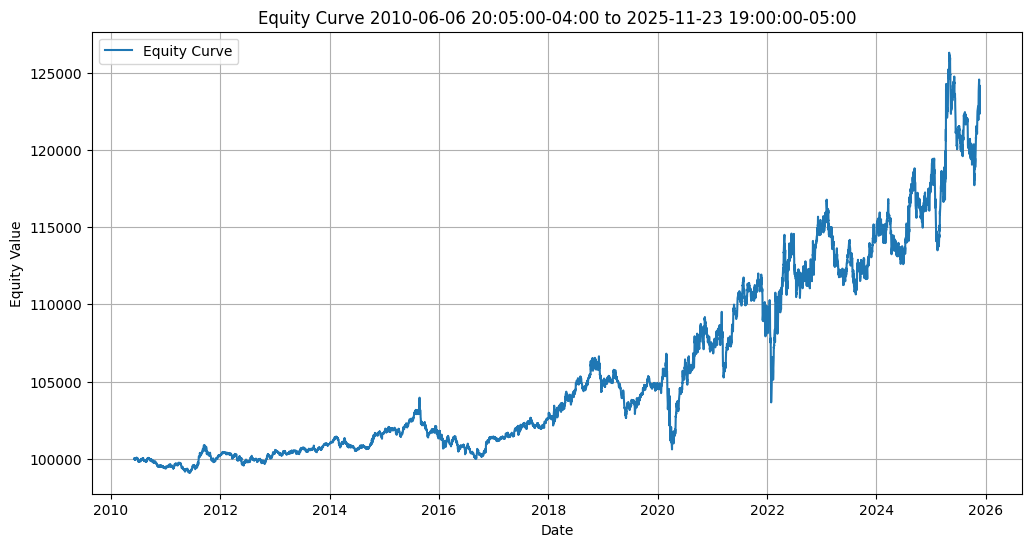

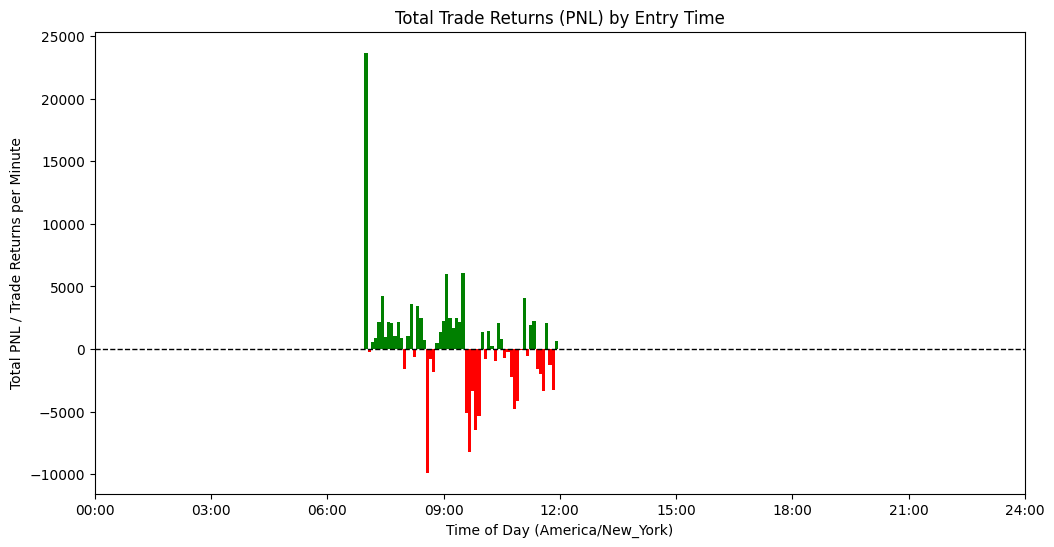

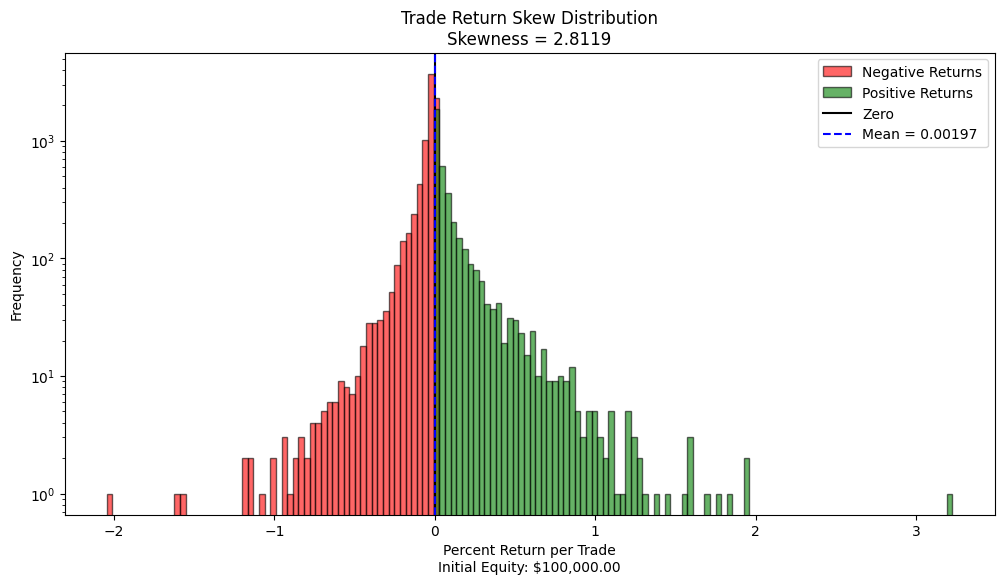

In [ ]:
bt = Backtester(
    data.get_ohlc_prices(),
    data.get_indicies(),
    df['signal'],
    data.get_timeframe(),
    tick_value=0.5,
    contract_multiplier=2,
    slippage_ticks=0,
    commission=0
)
bt.full_backtest()
print(bt)
bt.generate_equity_curve().plot()
bt.generate_trade_time_distribution()
bt.generate_skew_curve().plot()
bt.monte_carlo_pnl_resampling_test(iterations=1000, pct_of_trades=1)